# EDA visual de SPHEREx: cómo se mueve un objeto entre visitas

Notebook para **ver** las imágenes, no para medir. Usa las mismas funciones que el prototipo
(`prototipos/rango_fechas/spherex.py`), así que las imágenes son las mismas que ve la interfaz.

1. **Visitas**: en qué fechas SPHEREx observó la posición.
2. **Secuencia t-1, t, t+1**: tres visitas consecutivas alineadas norte-arriba, con la posición predicha por movimiento propio.
3. **Restas**: qué cambió entre una visita y la siguiente (rojo = aparece, azul = desaparece).
4. **Parpadeo animado** de todas las visitas.
5. **Otra banda**: la misma secuencia en una segunda banda (otra longitud de onda).

Cambia la celda de configuración y vuelve a correr todo (*Run All*). Los recortes se guardan en
`data/cache/prototipo/` y la segunda vez no se descargan.

In [1]:
import sys, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
import yaml
from astropy.time import Time

RAIZ = Path.cwd()
while not (RAIZ / "prototipos").exists() and RAIZ != RAIZ.parent:   # funciona desde data/ o desde la raíz
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "prototipos" / "rango_fechas"))
import spherex

warnings.filterwarnings("ignore")
plt.rcParams["animation.embed_limit"] = 50  # MB, para que la animación quepa en el notebook
# Píxeles sin dato (núcleo saturado, rayos cósmicos, fuera del detector) en morado, para no confundirlos con brillo.
GRIS = plt.get_cmap("gray").copy(); GRIS.set_bad("#6a2c8a")
DIF = plt.get_cmap("RdBu_r").copy(); DIF.set_bad("#6a2c8a")

## 0. Configuración

| id | qué se espera |
|---|---|
| `barnard` | movimiento grande y brillante: el caso más claro (banda 2) |
| `wise_0855` | movimiento grande pero débil: subir `POR_VISITA` a 4–6 (banda 5) |
| `eps_ind_b` | enana marrón, roja (bandas 5–6) |
| `rw_aur`, `r_dra` | control: varían de brillo pero **no** se mueven |

`T` es el índice de la visita central (`None` = la del medio). `DESPLAZAMIENTOS` define qué visitas se muestran
alrededor de `T`: `(-1, 0, 1)` es t-1, t, t+1; `(-1, 0, 2)` es t-1, t, t+2.

In [2]:
CAMPO = "barnard"
BANDA = None              # None = la recomendada en data/campos_de_prueba.yml
BANDA_EXTRA = 4           # segunda banda para comparar (1-6), None para saltarse la sección 5
INICIO, FIN = "2025-04-01", Time.now().isot[:10]
SIZE = 0.1                # grados de lado del recorte (0.1° ≈ 59 px de 6.15")
POR_VISITA = 3            # exposiciones sumadas (mediana) por visita: más = menos ruido, más descarga
T = None                  # visita central; None = la del medio
DESPLAZAMIENTOS = (-1, 0, 1)
ZOOM_PX = None            # p. ej. 25 para recortar al centro; None = recorte entero

campos = {c["id"]: c for c in yaml.safe_load((RAIZ / "data" / "campos_de_prueba.yml").read_text())["campos"]}
c = campos[CAMPO]
BANDA = BANDA or c["banda_recomendada"]

def posicion(anio):
    """Posición J2000 del catálogo propagada con el movimiento propio (lineal, sin paralaje)."""
    dt = anio - 2000.0
    dec = c["dec_deg"] + c["pmdec"] * dt / 3.6e6
    ra = c["ra_deg"] + c["pmra"] * dt / 3.6e6 / math.cos(math.radians(c["dec_deg"]))
    return ra % 360, dec

anio_medio = (Time(INICIO).decimalyear + Time(FIN).decimalyear) / 2
RA, DEC = posicion(anio_medio)
N_PX = int(math.ceil(SIZE * 3600 / spherex.ESCALA_ARCSEC))
W = spherex.wcs_destino(RA, DEC, N_PX)       # rejilla común norte-arriba, este a la izquierda
pm = math.hypot(c["pmra"], c["pmdec"]) / 1000
print(f"{c['nombre']} | banda {BANDA} {spherex.BANDAS_UM[BANDA]} µm | centro RA {RA:.5f} Dec {DEC:.5f} (época {anio_medio:.2f})")
print(f"Movimiento propio: {pm:.2f}\"/año = {pm/spherex.ESCALA_ARCSEC:.2f} px/año | recorte {N_PX}x{N_PX} px")

Estrella de Barnard | banda 2 (1.1, 1.62) µm | centro RA 269.44626 Dec 4.76837 (época 2026.06)
Movimiento propio: 10.39"/año = 1.69 px/año | recorte 59x59 px


## 1. Visitas disponibles

Una consulta SIA2 (barata: no baja imágenes). Las exposiciones a menos de 5 días se agrupan en una *visita*.

In [3]:
def visitas_de(banda):
    obs, avisos = spherex.buscar(RA, DEC, banda, INICIO, FIN)
    for a in avisos: print("AVISO:", a)
    return spherex.agrupar_visitas(obs)

visitas = visitas_de(BANDA)
pd.DataFrame([dict(visita=i, inicio=v[0].iso[:10], fin=v[-1].iso[:10], exposiciones=len(v),
                   dias_desde_la_primera=round(v[0].mjd - visitas[0][0].mjd, 1))
              for i, v in enumerate(visitas)])

,visita,inicio,fin,exposiciones,dias_desde_la_primera
0,0,2025-08-21,2025-08-30,18,0.0
1,1,2026-03-15,2026-03-22,19,205.1
2,2,2026-08-18,2026-08-28,24,361.9
3,3,2026-09-22,2026-09-22,1,396.6


## 2. Cargar y alinear las visitas

Por cada visita se bajan `POR_VISITA` recortes, se les resta la luz zodiacal, se enmascaran píxeles malos,
se **reproyectan** a la rejilla común (cada apuntado viene girado distinto) y se combinan con la mediana.

In [4]:
def cargar(banda, visitas):
    grupos = spherex.elegir_fotogramas(visitas, max_visitas=len(visitas), por_visita=POR_VISITA)
    fot = []
    for i, g in enumerate(grupos):
        print(f"\rbanda {banda}: visita {i+1}/{len(grupos)}", end="")
        f = spherex.apilar([spherex.procesar(spherex.bajar_recorte(o, RA, DEC, SIZE), o, RA, DEC, N_PX) for o in g])
        f.datos = f.datos - np.nanmedian(f.datos)          # fondo a 0 para comparar entre visitas
        fot.append(f)
    print()
    return fot

fot = cargar(BANDA, visitas)

def etiqueta(f):
    lam = f"{f.lambda_um:.3f} µm" if f.lambda_um else "λ ?"
    return f"{f.obs.iso[:10]} · {lam} · {f.n_apiladas} exp."

def norma(fs):
    """Una misma escala para todas las imágenes: si no, los cambios de brillo se inventan."""
    todo = np.concatenate([f.datos[np.isfinite(f.datos)] for f in fs])
    lo, hi = np.percentile(todo, [1, 99.7])
    a = 0.1
    def estirar(d):                       # asinh entre lo y hi; los NaN siguen siendo NaN (morado)
        x = np.clip((d - lo) / (hi - lo), 0, 1)
        return np.ma.masked_invalid(np.arcsinh(x / a) / np.arcsinh(1 / a))
    return estirar

def anio(f):
    return Time(f.obs.mjd, format="mjd").decimalyear

def marcar(ax, f, color="lime"):
    """Círculo en la posición predicha por movimiento propio en la fecha de la imagen."""
    x, y = W.world_to_pixel_values(*posicion(anio(f)))
    ax.add_patch(plt.Circle((x, y), 3, fill=False, color=color, lw=1.2))

def encuadrar(ax):
    ax.set_xticks([]); ax.set_yticks([])
    if ZOOM_PX:
        m = N_PX / 2
        ax.set_xlim(m - ZOOM_PX / 2, m + ZOOM_PX / 2); ax.set_ylim(m - ZOOM_PX / 2, m + ZOOM_PX / 2)

print(f"{len(fot)} visitas cargadas")

banda 2: visita 3/4

banda 2: visita 4/4
4 visitas cargadas


## 3. Secuencia t-1, t, t+1

Arriba, las tres visitas con **la misma escala de grises**. El círculo verde es donde el movimiento propio dice
que debería estar el objeto en esa fecha: si el objeto se mueve, la mancha sigue al círculo.
Abajo, la resta entre visitas consecutivas: un par **azul → rojo** es un objeto que se desplazó.
Norte arriba, este a la izquierda. **Morado = sin dato** (núcleo saturado o píxel enmascarado).
Los dipolos pequeños en estrellas quietas vecinas son restos de alineación y de PSF, no movimiento.

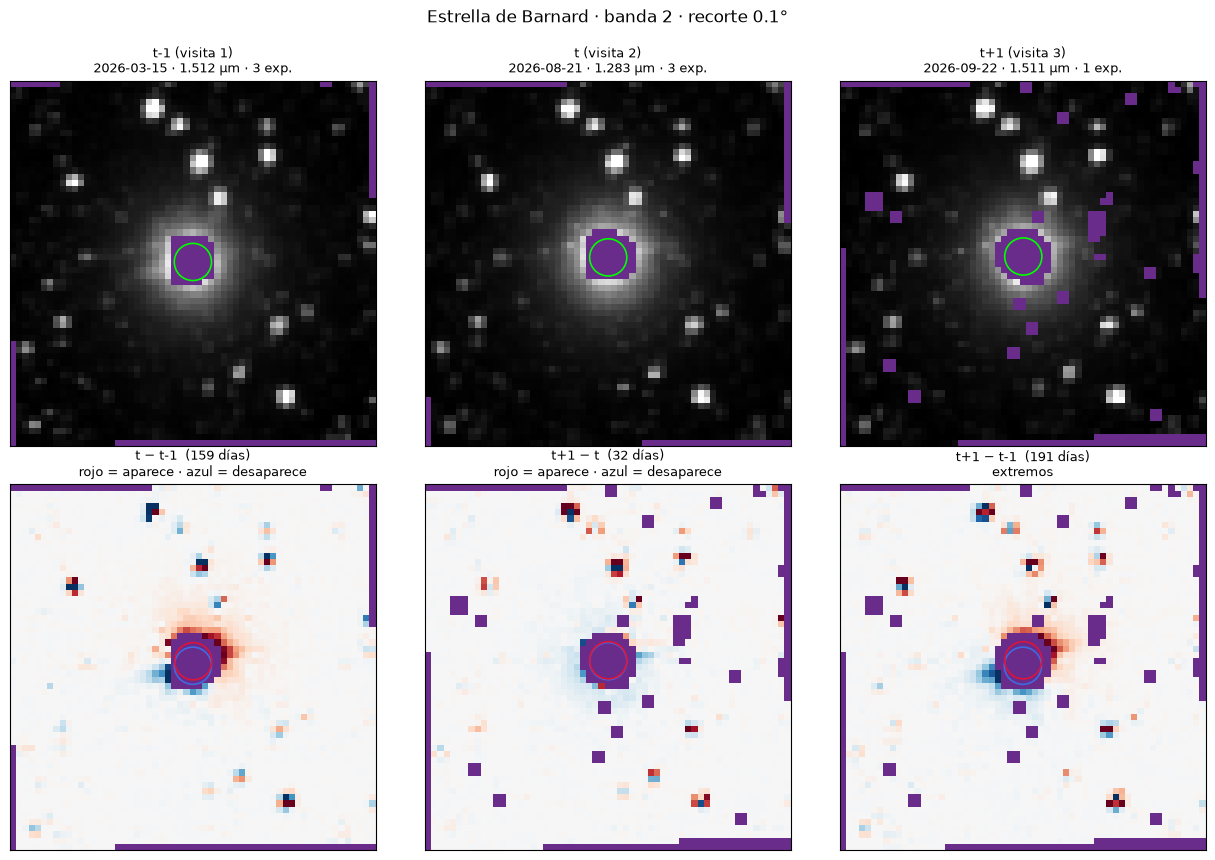

Ojo: las visitas están a λ distintas (1.283–1.512 µm): parte del cambio de brillo es el filtro lineal variable, no el objeto.


In [5]:
def secuencia(fot, banda, T=T, despl=DESPLAZAMIENTOS):
    t = len(fot) // 2 if T is None else T
    idx = [t + d for d in despl if 0 <= t + d < len(fot)]
    nombres = {i: ("t" if i == t else f"t{i - t:+d}") for i in idx}
    if len(idx) < len(despl):
        print(f"Aviso: con T={t} y {len(fot)} visitas solo existen {[nombres[i] for i in idx]}")
    sel = [fot[i] for i in idx]
    n = norma(sel)
    fig, axs = plt.subplots(2, len(sel), figsize=(4.2 * len(sel), 8.6), squeeze=False)
    for k, (i, f) in enumerate(zip(idx, sel)):
        ax = axs[0, k]
        ax.imshow(n(f.datos), origin="lower", cmap=GRIS, vmin=0, vmax=1)
        marcar(ax, f); encuadrar(ax)
        ax.set_title(f"{nombres[i]} (visita {i})\n{etiqueta(f)}", fontsize=9)
    # restas consecutivas, con escala simétrica común
    restas = [(sel[k + 1].datos - sel[k].datos, f"{nombres[idx[k+1]]} − {nombres[idx[k]]}") for k in range(len(sel) - 1)]
    lim = np.nanpercentile(np.abs(np.concatenate([r[np.isfinite(r)] for r, _ in restas])), 99.5) if restas else 1
    for k, (r, titulo) in enumerate(restas):
        ax = axs[1, k]
        ax.imshow(r, origin="lower", cmap=DIF, vmin=-lim, vmax=lim)
        marcar(ax, sel[k], "royalblue"); marcar(ax, sel[k + 1], "crimson"); encuadrar(ax)
        dias = sel[k + 1].obs.mjd - sel[k].obs.mjd
        ax.set_title(f"{titulo}  ({dias:.0f} días)\nrojo = aparece · azul = desaparece", fontsize=9)
    # última casilla: resta entre los extremos (la base temporal más larga)
    ax = axs[1, -1]
    r = sel[-1].datos - sel[0].datos
    ax.imshow(r, origin="lower", cmap=DIF, vmin=-lim, vmax=lim)
    marcar(ax, sel[0], "royalblue"); marcar(ax, sel[-1], "crimson"); encuadrar(ax)
    ax.set_title(f"{nombres[idx[-1]]} − {nombres[idx[0]]}  ({sel[-1].obs.mjd - sel[0].obs.mjd:.0f} días)\nextremos", fontsize=9)
    fig.suptitle(f"{c['nombre']} · banda {banda} · recorte {SIZE}°", y=0.995)
    fig.tight_layout(); plt.show()
    lams = [f.lambda_um for f in sel if f.lambda_um]
    if lams and max(lams) - min(lams) > 0.02:
        print(f"Ojo: las visitas están a λ distintas ({min(lams):.3f}–{max(lams):.3f} µm): parte del cambio de brillo "
              "es el filtro lineal variable, no el objeto.")

secuencia(fot, BANDA)

## 4. Parpadeo de todas las visitas

La animación recorre todas las visitas en orden de fecha con la misma escala. Usa los controles para pausar,
ir cuadro a cuadro o cambiar la velocidad.

In [6]:
def parpadeo(fot, banda, ms=700):
    n = norma(fot)
    fig, ax = plt.subplots(figsize=(5.5, 5.8))
    im = ax.imshow(n(fot[0].datos), origin="lower", cmap=GRIS, vmin=0, vmax=1)
    circ = plt.Circle((0, 0), 3, fill=False, color="lime", lw=1.2); ax.add_patch(circ)
    encuadrar(ax)
    tit = ax.set_title("")
    def paso(i):
        f = fot[i]
        im.set_data(n(f.datos))
        circ.center = W.world_to_pixel_values(*posicion(anio(f)))
        tit.set_text(f"{c['nombre']} · banda {banda}\nvisita {i}: {etiqueta(f)}")
        return im, circ, tit
    an = animation.FuncAnimation(fig, paso, frames=len(fot), interval=ms)
    plt.close(fig)
    return HTML(an.to_jshtml(default_mode="loop"))

parpadeo(fot, BANDA)

### Todas las visitas en una rejilla

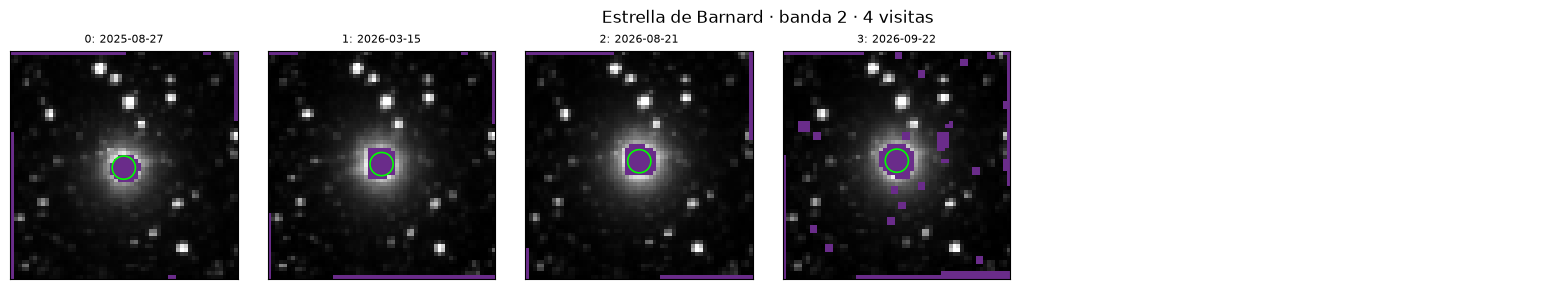

In [7]:
def rejilla(fot, banda, cols=6):
    n = norma(fot)
    filas = math.ceil(len(fot) / cols)
    fig, axs = plt.subplots(filas, cols, figsize=(2.6 * cols, 2.9 * filas), squeeze=False)
    for ax in axs.flat: ax.axis("off")
    for i, f in enumerate(fot):
        ax = axs.flat[i]; ax.axis("on")
        ax.imshow(n(f.datos), origin="lower", cmap=GRIS, vmin=0, vmax=1); marcar(ax, f); encuadrar(ax)
        ax.set_title(f"{i}: {f.obs.iso[:10]}", fontsize=8)
    fig.suptitle(f"{c['nombre']} · banda {banda} · {len(fot)} visitas"); fig.tight_layout(); plt.show()

rejilla(fot, BANDA)

## 5. Otra banda

La misma secuencia en `BANDA_EXTRA`. Es otra longitud de onda (otro detector), así que las estrellas cambian de brillo
relativo: los objetos fríos, como las enanas marrones, son más brillantes en las bandas 5–6. Las fechas de cada banda
son casi las mismas porque SPHEREx observa con los seis detectores a la vez, pero cada detector apunta a una zona
distinta del cielo, así que la misma posición se cubre en exposiciones distintas.

Banda 4: (2.42, 3.82) µm


banda 4: visita 3/4

banda 4: visita 4/4


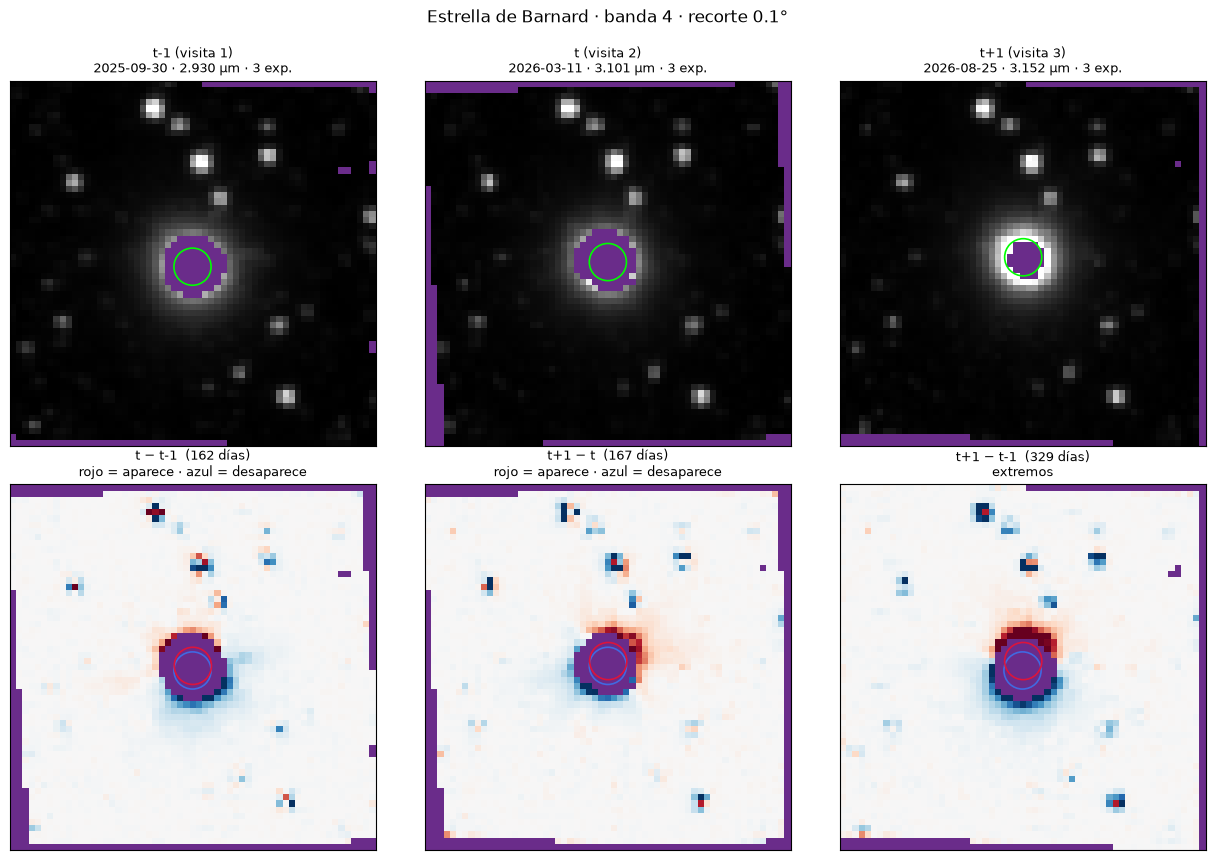

Ojo: las visitas están a λ distintas (2.930–3.152 µm): parte del cambio de brillo es el filtro lineal variable, no el objeto.


In [8]:
if BANDA_EXTRA:
    print(f"Banda {BANDA_EXTRA}: {spherex.BANDAS_UM[BANDA_EXTRA]} µm")
    visitas_extra = visitas_de(BANDA_EXTRA)
    fot_extra = cargar(BANDA_EXTRA, visitas_extra)
    secuencia(fot_extra, BANDA_EXTRA)

In [9]:
if BANDA_EXTRA:
    display(parpadeo(fot_extra, BANDA_EXTRA))

### Las dos bandas lado a lado en la misma visita

Para cada visita de la banda principal se busca la visita más cercana en fecha de la otra banda.

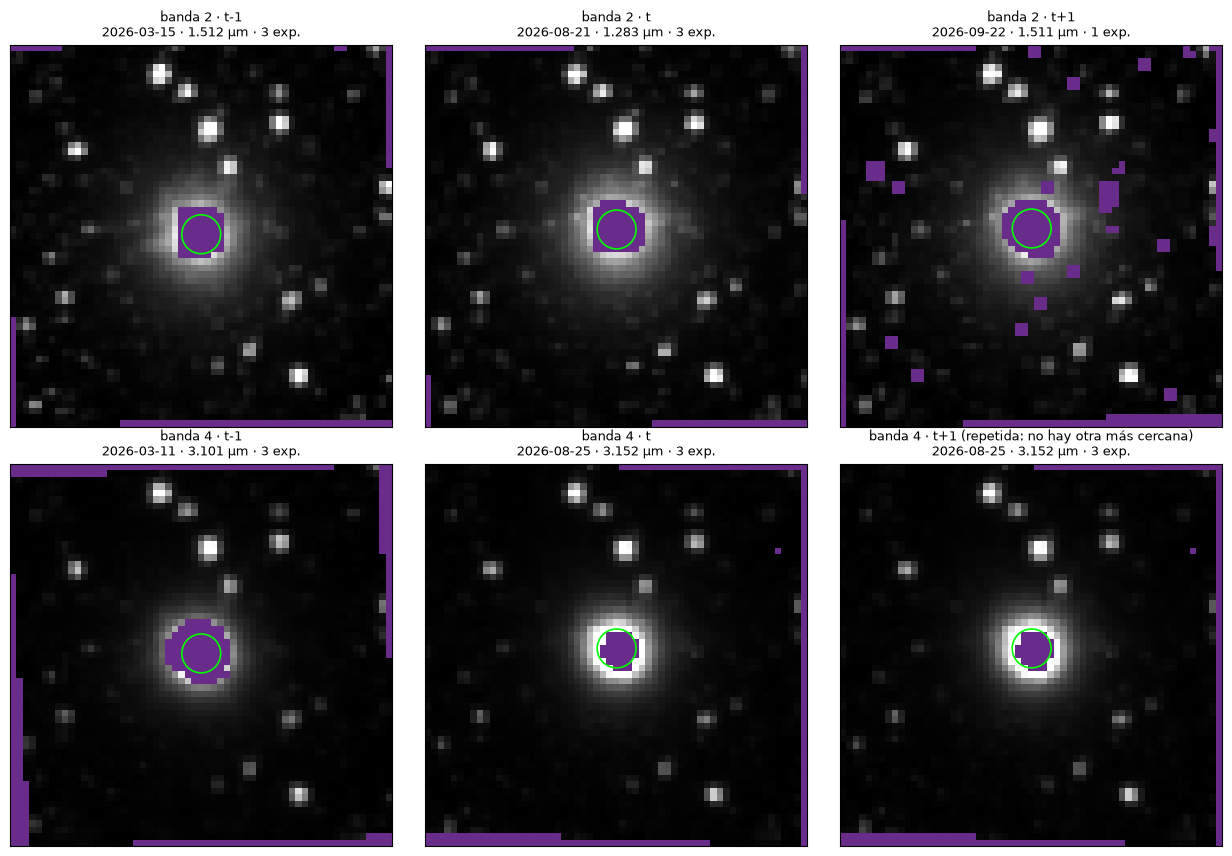

In [10]:
if BANDA_EXTRA:
    t = len(fot) // 2 if T is None else T
    idx = [t + d for d in DESPLAZAMIENTOS if 0 <= t + d < len(fot)]
    fig, axs = plt.subplots(2, len(idx), figsize=(4.2 * len(idx), 8.6), squeeze=False)
    for fila, (fs, b) in enumerate([(fot, BANDA), (fot_extra, BANDA_EXTRA)]):
        n = norma(fs); usado = []
        for k, i in enumerate(idx):
            ref = fot[i].obs.mjd
            f = min(fs, key=lambda x: abs(x.obs.mjd - ref))
            ax = axs[fila, k]
            ax.imshow(n(f.datos), origin="lower", cmap=GRIS, vmin=0, vmax=1); marcar(ax, f); encuadrar(ax)
            rep = " (repetida: no hay otra más cercana)" if fila and k and f is usado[-1] else ""
            usado.append(f)
            ax.set_title(f"banda {b} · t{i - t:+d}{rep}\n{etiqueta(f)}".replace("t+0", "t"), fontsize=9)
    fig.tight_layout(); plt.show()

---
**Qué NO prueba este notebook:** las imágenes son la mediana de pocas exposiciones y la escala es visual (asinh).
No es fotometría ni astrometría. Para medir el desplazamiento ver `prototipos/rango_fechas/eda_spherex.ipynb`, sección 5.

*This notebook makes use of data products from SPHEREx, a joint project of the Jet Propulsion Laboratory and the
California Institute of Technology, funded by the National Aeronautics and Space Administration.*